# Learning to Rank

**Concept.** A price series is just daily returns stacked on top of each other. Two numbers describe an asset:

- **Mean return:** how much it earns on average per year.
- **Volatility:** how much it jumps around, measured as the standard deviation of returns per year.

Everything in the paper is built on these two. For example, the volatility scaling uses σ to put less money on assets that move a lot.

We simulate one asset where we know the true values, then check whether we can recover them from the data.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## Simulate 10 years

<Axes: title={'center': 'One simulated asset'}>

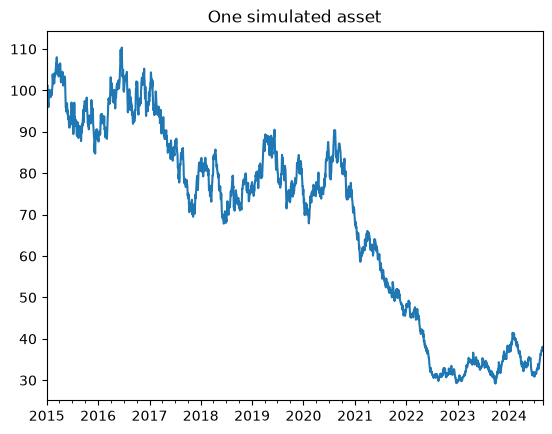

In [2]:
n_days = 252 * 10        # about 252 trading days per year
mu_annual = 0.05         # true mean return: 5% per year
sigma_annual = 0.20      # true volatility: 20% per year

mu_daily = mu_annual / 252
sigma_daily = sigma_annual / np.sqrt(252)

daily_returns = rng.normal(mu_daily, sigma_daily, n_days)
dates = pd.bdate_range("2015-01-01", periods=n_days)
prices = pd.Series(100 * np.cumprod(1 + daily_returns), index=dates)

prices.plot(title="One simulated asset")

## Estimate the two numbers back from the prices

In [3]:
rets = prices.pct_change().dropna()
print("estimated annual mean:", rets.mean() * 252)
print("estimated annual vol: ", rets.std() * np.sqrt(252))

estimated annual mean: -0.07888666954036141
estimated annual vol:  0.2010770297177648
